# V1DD 1196 UMAPs by cell type

Read the two r84 UMAP embeddings from CCM and plot them using the stored subclass cell-type colors, following the Minnie UMAP notebook.

Run [etl_v1dd1196_01.ipynb](etl_v1dd1196_01.ipynb), including its **cell type colors** and **embeddings** sections, first. This notebook uses the configured output root and does not recompute embeddings or modify CCM tables.

- **QC-nonnull:** source coordinates `qc_nonnull_embed0` / `qc_nonnull_embed1`.
- **Axon-dendrite reference:** source coordinates `ad_ref_embed0` / `ad_ref_embed1`.

Each panel retains its own available cells with subclass annotations; the two embeddings are not restricted to their intersection. Cells without subclass annotations are excluded and counted below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import read_embedding_locations
from connects_common_connectivity.io.path_spec import MODEL_TABLE_PATHS

In [2]:
OUTPUT_ROOT = Path(get_settings().output_root)
PROJECT_ID = "v1dd_1196"
HIERARCHY_ID = "v1dd_1196_cell_types"
EMBEDDING_TITLES = {
    "v1dd_r84_qc_nonnull_umap": "V1DD r84 QC-nonnull UMAP",
    "v1dd_r84_ad_ref_umap": "V1DD r84 axon-dendrite reference UMAP",
}

required_tables = ["Cluster", "ClusterMembership", "EmbeddingLocation"]
missing_paths = [
    OUTPUT_ROOT / MODEL_TABLE_PATHS[table]
    for table in required_tables
    if not (OUTPUT_ROOT / MODEL_TABLE_PATHS[table]).is_dir()
]
assert not missing_paths, (
    f"Missing CCM tables: {missing_paths}. Run etl_v1dd1196_01.ipynb first."
)

## Read subclass labels and colors

Memberships include multiple hierarchy levels. Keep only level-2 subclasses so each cell appears once, and reuse the same palette in both panels.

In [3]:
cell_type_colors = (
    pl.read_delta(OUTPUT_ROOT / MODEL_TABLE_PATHS["Cluster"])
    .filter(
        (pl.col("hierarchy_id") == HIERARCHY_ID)
        & (pl.col("level") == 2)
    )
    .select(pl.col("id").alias("cell_type"), "hex_color")
    .sort("cell_type")
)
assert not cell_type_colors.is_empty(), (
    "No V1DD subclasses found; run etl_v1dd1196_01.ipynb first."
)
assert cell_type_colors["cell_type"].n_unique() == cell_type_colors.height
assert cell_type_colors["hex_color"].null_count() == 0, (
    "Missing V1DD subclass colors; run the cell type colors section of "
    "etl_v1dd1196_01.ipynb first."
)

cell_types = (
    pl.read_delta(OUTPUT_ROOT / MODEL_TABLE_PATHS["ClusterMembership"])
    .filter(
        (pl.col("project_id") == PROJECT_ID)
        & (pl.col("hierarchy_id") == HIERARCHY_ID)
    )
    .select(
        pl.col("item").alias("dataitem_id"),
        pl.col("cluster").alias("cell_type"),
    )
    .join(cell_type_colors, on="cell_type", how="inner", validate="m:1")
)
assert not cell_types.is_empty(), (
    "No V1DD subclass memberships found; run etl_v1dd1196_01.ipynb first."
)
assert cell_types["dataitem_id"].n_unique() == cell_types.height, (
    "Expected exactly one subclass membership per V1DD cell."
)
cell_type_palette = dict(cell_type_colors.iter_rows())
cell_type_order = cell_type_colors["cell_type"].to_list()
print(f"V1DD cells with subclass annotations: {cell_types.height:,}")

V1DD cells with subclass annotations: 57,790


## Read the two stored UMAPs

In [4]:
plot_nodes_by_space = {}
for embedding_space, title in EMBEDDING_TITLES.items():
    locations = read_embedding_locations(
        PROJECT_ID,
        embedding_space_ids=embedding_space,
        output_root=OUTPUT_ROOT,
    )
    assert not locations.is_empty(), (
        f"No coordinates for {embedding_space}; run the embeddings section of "
        "etl_v1dd1196_01.ipynb first."
    )
    assert locations["dataitem_id"].n_unique() == locations.height, (
        f"Duplicate cell coordinates in {embedding_space}."
    )
    assert locations.filter(
        pl.col("x").is_finite() & pl.col("y").is_finite()
    ).height == locations.height, f"Non-finite coordinates in {embedding_space}."

    plot_nodes = locations.join(
        cell_types, on="dataitem_id", how="inner", validate="1:1"
    )
    assert not plot_nodes.is_empty(), f"No subclass-labeled cells in {embedding_space}."
    plot_nodes_by_space[embedding_space] = plot_nodes
    print(
        f"{title}: {locations.height:,} stored; {plot_nodes.height:,} plotted; "
        f"{locations.height - plot_nodes.height:,} without subclass annotations"
    )

V1DD r84 QC-nonnull UMAP: 57,790 stored; 57,790 plotted; 0 without subclass annotations
V1DD r84 axon-dendrite reference UMAP: 39,114 stored; 39,114 plotted; 0 without subclass annotations


## Plot UMAPs by cell type

Colors and legend order are shared; coordinate axes are independent because these are different embedding spaces.

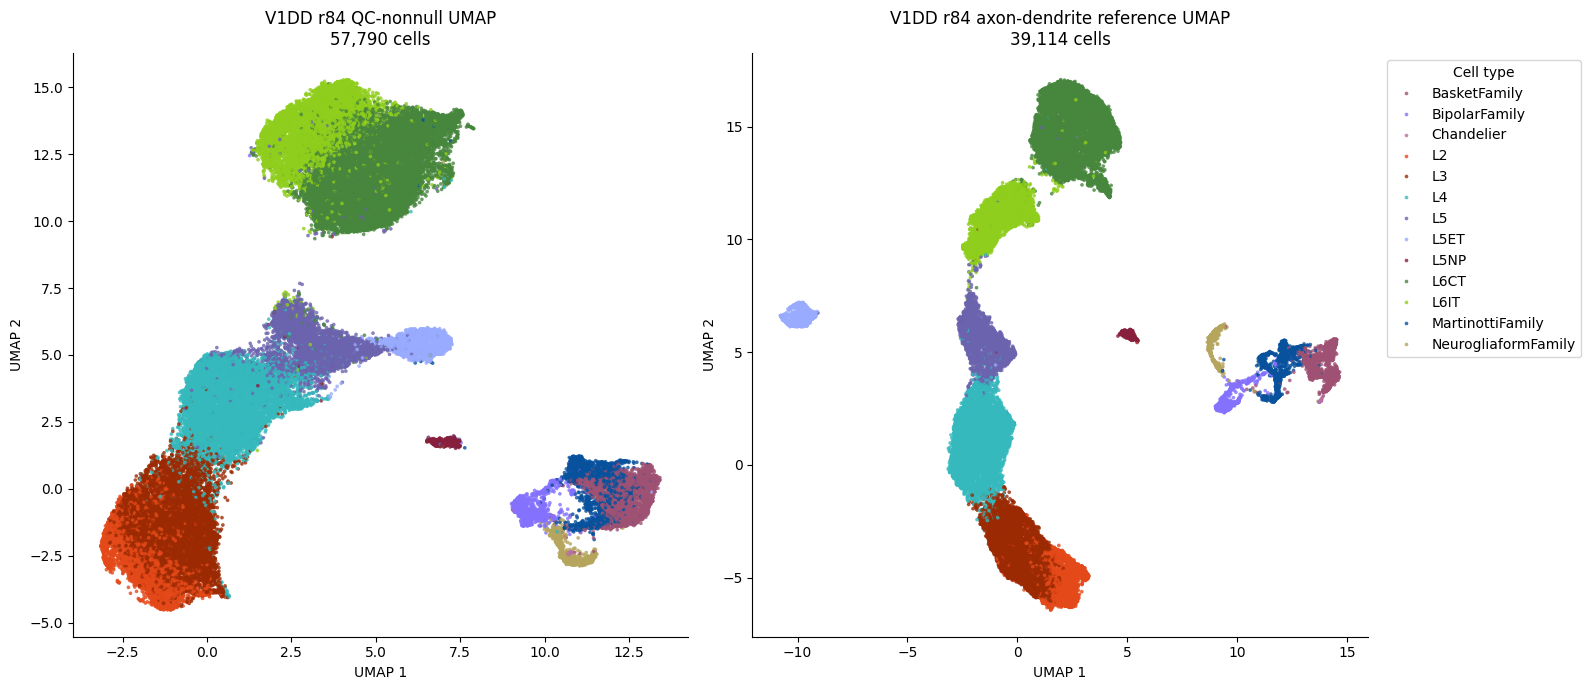

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(16, 7))
for index, (embedding_space, title) in enumerate(EMBEDDING_TITLES.items()):
    axis = axes[index]
    plot_nodes = plot_nodes_by_space[embedding_space]
    sns.scatterplot(
        data=plot_nodes.to_pandas(),
        x="x",
        y="y",
        hue="cell_type",
        hue_order=cell_type_order,
        palette=cell_type_palette,
        s=7,
        linewidth=0,
        alpha=0.8,
        legend="full" if index == 1 else False,
        ax=axis,
    )
    axis.set(
        title=f"{title}\n{plot_nodes.height:,} cells",
        xlabel="UMAP 1",
        ylabel="UMAP 2",
    )
    sns.despine(ax=axis)

axes[1].legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
figure.tight_layout()
plt.show()